# Experiment 3 — MovieLens random pairs: robustness across the real-data pair distribution

Figures per `docs/experiments.md`, Experiment 3 "Figures" subsection. This notebook only loads `results/exp3_1/results.parquet`, `results/exp3_2/results.parquet`, `results/exp3_3/results.parquet` and plots — it never recomputes (see CLAUDE.md and `docs/experiments.md` §0.4). Run `python -m scripts.run_experiment3` (or `SMOKE_TEST=1 python -m scripts.run_experiment3` first) to generate them.

**Note:** this experiment was originally built and run as "Experiment 4"; a separate, older, fixed-instance "Experiment 3" has been dropped entirely and this took its number (see `docs/experiments.md`'s Experiment 3 "RENUMBERING NOTE" and "REVISION 4"). REVISION 4 also changed the algorithm roster, version thresholds, `budget_cap`, and scale -- this notebook is run against the real, complete 50-rep run under this config.

Each version reports 6 algorithm rows per rep: `kabc`, `kabc-0.5x` (kabc re-run at 0.5× its own realized τ — tests how conservative its stopping rule is), `acb`, `tas-fw`, and two `unif-kkm` variants (`unif-kkm-1x`/`unif-kkm-0.5x` = that same rep's kabc τ, ×1 or ×0.5, capped at `budget_cap` — see docs/experiments.md's "KABC-0.5X and UNIF-KKM VARIANTS"). **Multiplier note (2026-09-14):** this was originally 0.9x; changed to 0.5x once direct per-rep inspection (Experiment 2's data) showed KABC's doubling-trick schedule quantizes its own realized τ to a small set of round-boundary checkpoints (the final round alone typically costs roughly half of the total realized τ), so a 0.9x cut cannot actually test "10% less budget" — it almost always lands in the same "one checkpoint short" bucket as a much larger cut would.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kabc.plotting import set_style, savefig, ALGO_ORDER, ALGO_COLORS, ALGO_LABELS

set_style()

VERSIONS = ["exp3_1", "exp3_2", "exp3_3"]
VERSION_TITLES = {
    "exp3_1": "exp3_1: tight gap, argmax MMD² (gap ≤ 0.25)",
    "exp3_2": "exp3_2: moderate-large gap, uniform (0.25 ≤ gap ≤ 1.0)",
    "exp3_3": "exp3_3: tight gap, uniform (gap ≤ 0.25)",
}

dfs = {}
for version in VERSIONS:
    path = Path(f"../results/{version}/results.parquet")
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. Run `python -m scripts.run_experiment3` (or with SMOKE_TEST=1) "
            "to generate it -- this notebook only plots existing results, it never recomputes them."
        )
    dfs[version] = pd.read_parquet(path)
    print(f"loaded {len(dfs[version])} rows from {path}")

dfs[VERSIONS[0]].head()


loaded 300 rows from ../results/exp3_1/results.parquet
loaded 300 rows from ../results/exp3_2/results.parquet
loaded 300 rows from ../results/exp3_3/results.parquet


,exp_id,version,algorithm,rep,seed,budget_cap,tau,stopped,wall_clock_seconds,partition,error,ari,n_iterations,movie_id_a,movie_id_b,title_a,title_b,mean_a,mean_b,mmd2_ab
0,3,exp3_1,kabc,0,3000100,15000,3112,True,0.402171,"[0, 0, 0, 0, 1, 1, 1, 1]",0,1.0,4,1961,296,Rain Man (1988),Pulp Fiction (1994),4.053383,4.278213,0.051624
1,3,exp3_1,kabc-0.5x,0,3000101,1556,1408,False,0.279465,"[0, 0, 0, 0, 0, 0, 0, 0]",1,0.0,4,1961,296,Rain Man (1988),Pulp Fiction (1994),4.053383,4.278213,0.051624
2,3,exp3_1,acb,0,3000102,15000,14994,False,0.657332,"[0, 0, 0, 0, 0, 0, 0, 0]",1,0.0,8,1961,296,Rain Man (1988),Pulp Fiction (1994),4.053383,4.278213,0.051624
3,3,exp3_1,tas-fw,0,3000103,15000,14220,True,623.107094,"[0, 0, 0, 0, 1, 1, 1, 1]",0,1.0,14212,1961,296,Rain Man (1988),Pulp Fiction (1994),4.053383,4.278213,0.051624
4,3,exp3_1,unif-kkm-1x,0,3000104,3112,3112,True,0.179032,"[1, 1, 1, 1, 0, 0, 0, 0]",0,1.0,0,1961,296,Rain Man (1988),Pulp Fiction (1994),4.053383,4.278213,0.051624


## Headline figure: the real sampled movie pair, one rep, all 3 versions

A single rep's ACTUAL sampled movie pair for each version, plotted as real rating histograms (`data/ml-1m-207/ratings.parquet`, not recomputed from any algorithm -- same category as notebook 02's headline figure, which draws real 2D sample scatters directly from `RingBlobEnv`). At `rep=0`, all three versions happen to share the same movie A (the shared candidate-order permutation's first eligible choice, see `docs/experiments.md`'s Experiment 3 "Version-specific B-selection rules") -- so this one rep directly shows how each version's own rule picks a DIFFERENT movie B against the identical movie A, which is exactly what separates the three versions' difficulty.

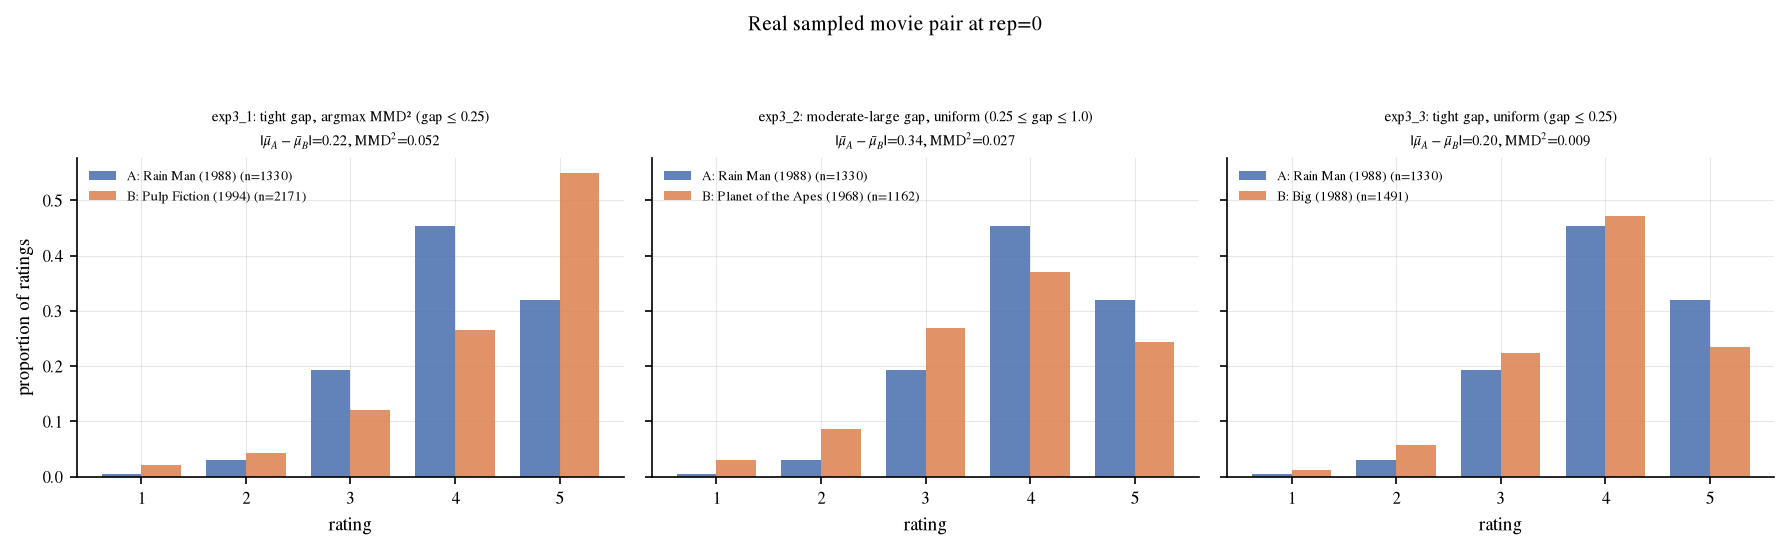

In [2]:
ratings = pd.read_parquet("../data/ml-1m-207/ratings.parquet")

HEADLINE_REP = 0  # arbitrary but fixed and real -- an actual rep from the completed run, not synthesized
RATING_VALUES = [1, 2, 3, 4, 5]
COLOR_A, COLOR_B = "#4C72B0", "#DD8452"  # neutral pair -- this figure isn't about algorithms, so deliberately not ALGO_COLORS

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, version in zip(axes, VERSIONS):
    row = dfs[version][dfs[version]["rep"] == HEADLINE_REP].iloc[0]
    pool_a = ratings.loc[ratings["movie_id"] == row["movie_id_a"], "rating"]
    pool_b = ratings.loc[ratings["movie_id"] == row["movie_id_b"], "rating"]
    props_a = pool_a.value_counts(normalize=True).reindex(RATING_VALUES, fill_value=0.0)
    props_b = pool_b.value_counts(normalize=True).reindex(RATING_VALUES, fill_value=0.0)

    x = np.arange(len(RATING_VALUES))
    width = 0.38
    ax.bar(x - width / 2, props_a.values, width, color=COLOR_A, alpha=0.88,
           label=f"A: {row['title_a']} (n={len(pool_a)})")
    ax.bar(x + width / 2, props_b.values, width, color=COLOR_B, alpha=0.88,
           label=f"B: {row['title_b']} (n={len(pool_b)})")
    ax.set_xticks(x)
    ax.set_xticklabels(RATING_VALUES)
    ax.set_xlabel("rating")
    ax.set_title(
        f"{VERSION_TITLES[version]}\n"
        rf"$|\bar\mu_A-\bar\mu_B|$={abs(row['mean_a'] - row['mean_b']):.2f}, "
        f"MMD$^2$={row['mmd2_ab']:.3f}",
        fontsize=7,
    )
    ax.legend(fontsize=6.5, frameon=False, loc="upper left")

axes[0].set_ylabel("proportion of ratings")
fig.suptitle(f"Real sampled movie pair at rep={HEADLINE_REP}", y=1.06, fontsize=10)
fig.tight_layout()
savefig(fig, "exp3_fig0_headline_pairs", fig_dir="../results/figures")
plt.show()

## Figures: four bar plots (ARI, τ, wall-clock/rep, convergence rate), each with all 3 versions × 6 algorithms

One bar plot per metric, not one figure per version: each plot has 18 bars grouped into 3 sets of 6 (one set per version: `exp3_1`, `exp3_2`, `exp3_3`), each set showing all 6 algorithm rows (`kabc`, `kabc-0.5x`, `acb`, `tas-fw`, `unif-kkm-1x`, `unif-kkm-0.5x`) side by side. Bar height = mean over reps; error bar = standard deviation over reps (not standard error — the spread itself is the point, since each rep is also a different randomly-sampled movie pair, not just different pull-noise on a fixed instance).

The convergence-rate plot (new, REVISION 4) is the fraction of reps with `stopped=True` per algorithm per version, using the same mean/std-over-reps convention (a Bernoulli mean ± its std across reps). Read it alongside the ARI plot, not in isolation: per `docs/experiments.md`'s caution, kabc's graceful trivial-cluster fallback (ARI exactly 0.0, `stopped=False`) can make a forced-guess baseline's ARI look artificially competitive, and a lower ARI for `kabc-0.5x` vs. primary `kabc` is the INTENDED signal (how much the extra half of budget bought), not a failure.


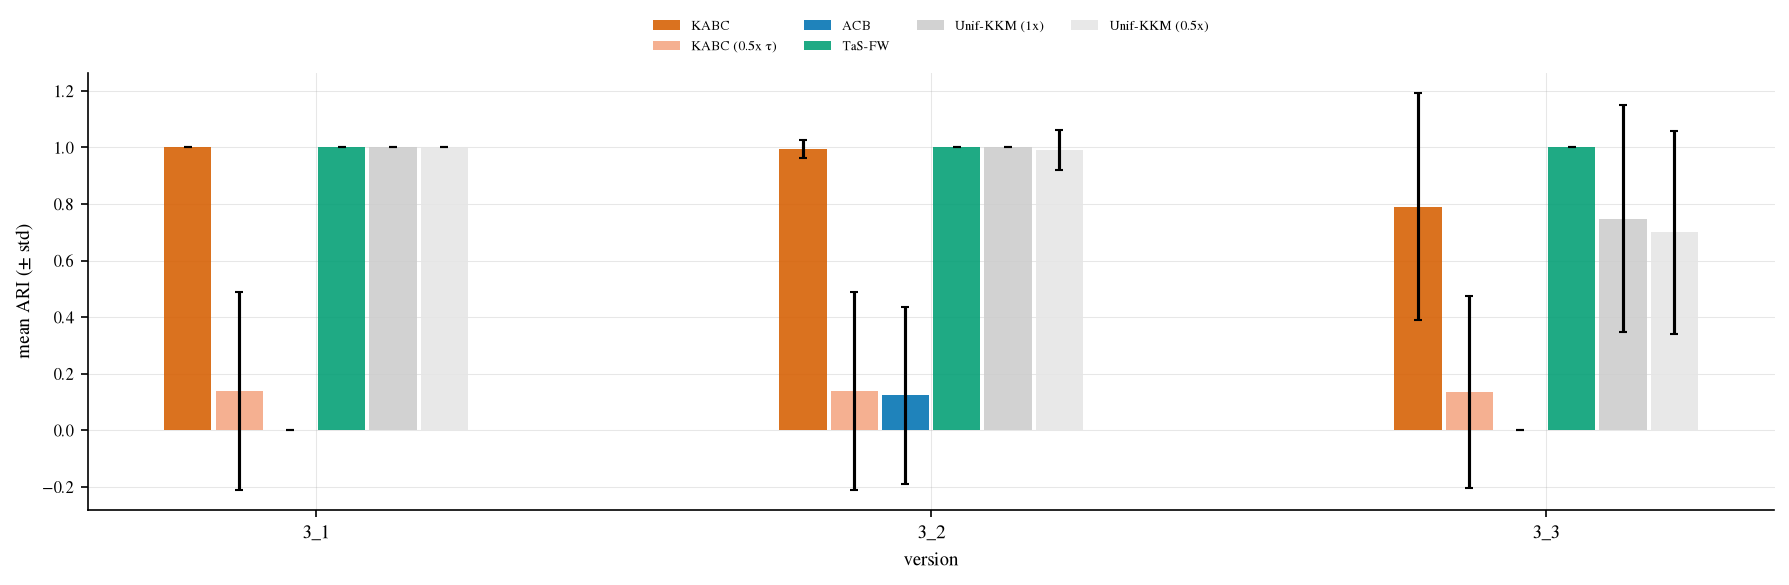

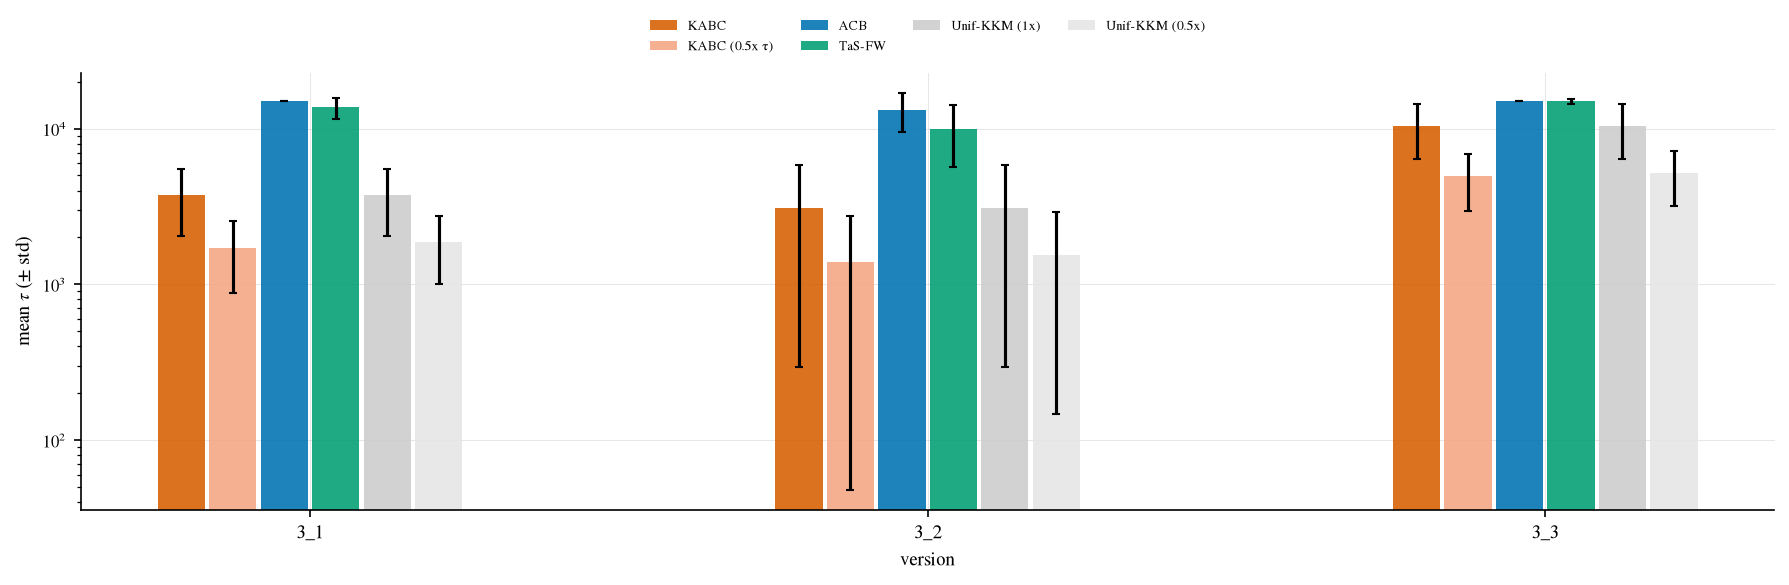

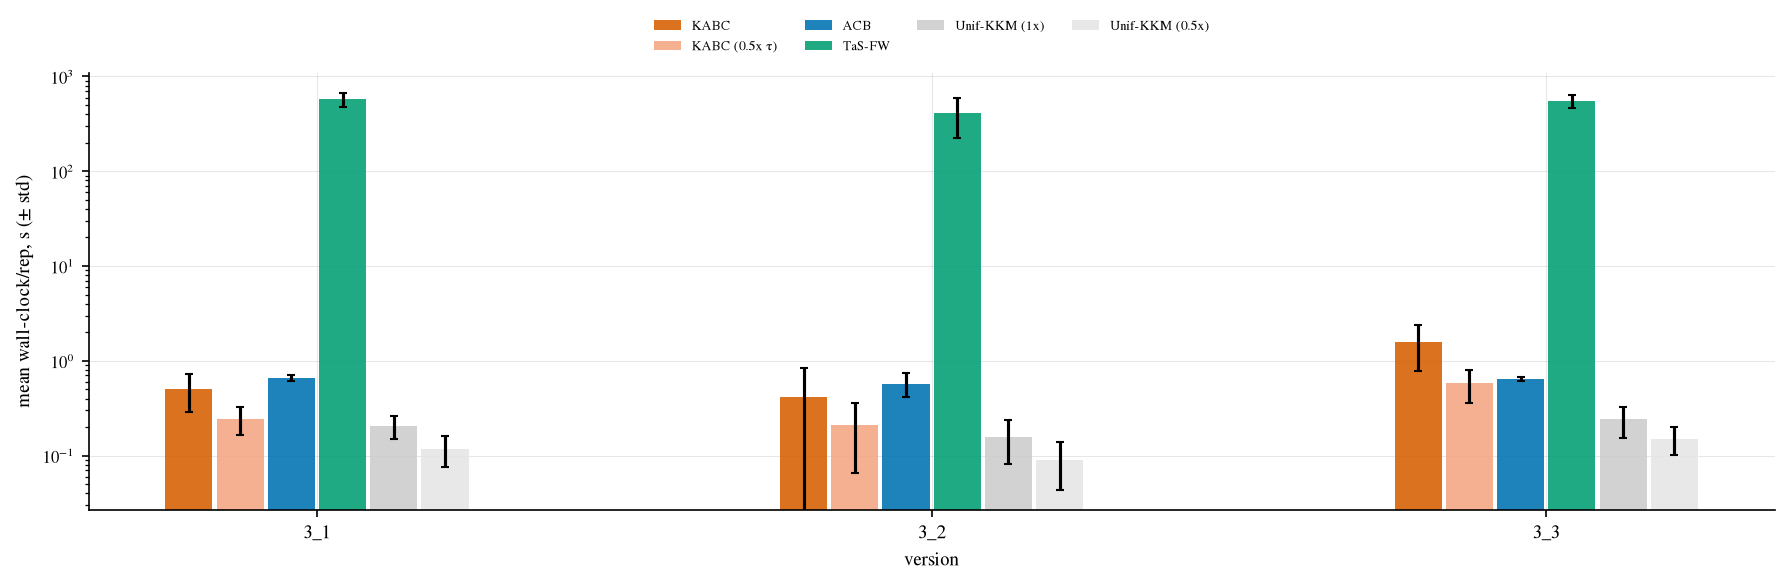

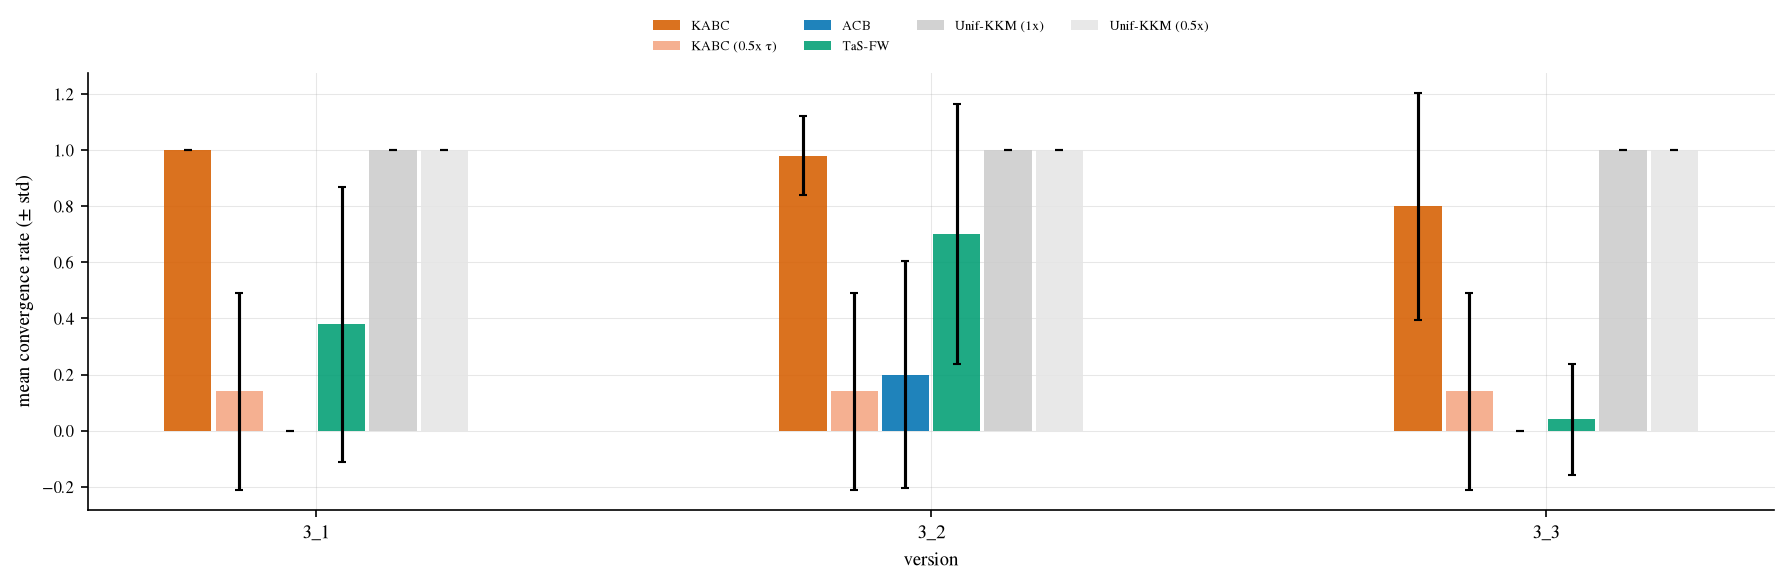

In [3]:
ALGOS = [a for a in ALGO_ORDER if a in dfs[VERSIONS[0]]["algorithm"].unique()]
assert len(ALGOS) == 6, f"expected 6 algorithm rows, got {len(ALGOS)}: {ALGOS}"

VERSION_SHORT = {"exp3_1": "3_1", "exp3_2": "3_2", "exp3_3": "3_3"}


def grouped_bar_plot(metric_col: str, ylabel: str, fig_name: str, log_scale: bool = False):
    """One bar plot: 3 sets (versions) x 6 bars (algorithms) = 18 bars total,
    grouped with a visible gap between sets so the 3 versions read as
    distinct clusters, not one continuous row of 18 bars."""
    n_algo = len(ALGOS)
    bar_width = 0.8 / n_algo
    group_gap = 0.6  # extra spacing between each version's cluster of 6 bars

    fig, ax = plt.subplots(figsize=(12, 4))
    xtick_positions, xtick_labels = [], []
    for v_idx, version in enumerate(VERSIONS):
        df = dfs[version]
        group_center = v_idx * (1.0 + group_gap)
        for a_idx, algo in enumerate(ALGOS):
            sub = df[df["algorithm"] == algo]
            mean = sub[metric_col].mean()
            std = sub[metric_col].std()
            x = group_center + (a_idx - (n_algo - 1) / 2) * bar_width
            ax.bar(x, mean, yerr=std, width=bar_width * 0.92, capsize=2,
                   color=ALGO_COLORS[algo], alpha=0.88,
                   label=ALGO_LABELS[algo] if v_idx == 0 else None)
        xtick_positions.append(group_center)
        xtick_labels.append(VERSION_SHORT[version])

    ax.set_xticks(xtick_positions)
    ax.set_xticklabels(xtick_labels, fontsize=9)
    ax.set_xlabel("version")
    ax.set_ylabel(ylabel)
    if log_scale:
        ax.set_yscale("log")
    ax.legend(fontsize=6.5, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.15))
    fig.tight_layout()
    savefig(fig, fig_name, fig_dir="../results/figures")
    plt.show()


grouped_bar_plot("ari", "mean ARI (± std)", "exp3_fig1_ari_bars")
grouped_bar_plot("tau", r"mean $\tau$ (± std)", "exp3_fig2_tau_bars", log_scale=True)
grouped_bar_plot("wall_clock_seconds", "mean wall-clock/rep, s (± std)", "exp3_fig3_wallclock_bars", log_scale=True)
grouped_bar_plot("stopped", "mean convergence rate (± std)", "exp3_fig4_convergence_bars")


## Summary tables: exact mean ± std per algorithm, per version

Printed (not just plotted) so the restricted-budget-style claims in the write-up can cite exact numbers, same convention as notebook 01's restricted-budget breakdowns. `frac_stopped` here is the same convergence-rate quantity as the new Figure 4 bar plot above, in table form.


In [4]:
for version in VERSIONS:
    df = dfs[version]
    algos_present = [a for a in ALGO_ORDER if a in df["algorithm"].unique()]
    rows = []
    for a in algos_present:
        sub = df[df["algorithm"] == a]
        rows.append({
            "algorithm": ALGO_LABELS[a],
            "mean_tau": sub["tau"].mean(),
            "std_tau": sub["tau"].std(),
            "mean_ari": sub["ari"].mean(),
            "std_ari": sub["ari"].std(),
            "mean_wall_clock_s": sub["wall_clock_seconds"].mean(),
            "std_wall_clock_s": sub["wall_clock_seconds"].std(),
            "frac_stopped": sub["stopped"].mean(),
            "std_stopped": sub["stopped"].std(),
        })
    print(f"=== {version} ===")
    display(pd.DataFrame(rows))


=== exp3_1 ===


,algorithm,mean_tau,std_tau,mean_ari,std_ari,mean_wall_clock_s,std_wall_clock_s,frac_stopped,std_stopped
0,KABC,3750.40,1720.546282,1.00,0.00000,0.503529,0.217408,1.00,0.000000
1,KABC (0.5x τ),1719.04,833.008243,0.14,0.35051,0.245095,0.082051,0.14,0.350510
2,ACB,14996.72,2.128907,0.00,0.00000,0.659441,0.050987,0.00,0.000000
3,TaS-FW,13660.26,2086.578244,1.00,0.00000,576.273649,95.220143,0.38,0.490314
4,Unif-KKM (1x),3750.40,1720.546282,1.00,0.00000,0.204428,0.054915,1.00,0.000000
5,Unif-KKM (0.5x),1872.64,861.244040,1.00,0.00000,0.117324,0.041814,1.00,0.000000


=== exp3_2 ===


,algorithm,mean_tau,std_tau,mean_ari,std_ari,mean_wall_clock_s,std_wall_clock_s,frac_stopped,std_stopped
0,KABC,3076.16,2782.127562,0.995484,0.031934,0.419653,0.429516,0.98,0.141421
1,KABC (0.5x τ),1396.80,1348.778677,0.140000,0.350510,0.210899,0.145714,0.14,0.350510
2,ACB,13252.12,3697.833374,0.123794,0.312629,0.574772,0.161343,0.20,0.404061
3,TaS-FW,9942.04,4246.814552,1.000000,0.000000,409.044359,184.400961,0.70,0.462910
4,Unif-KKM (1x),3076.16,2782.127562,1.000000,0.000000,0.158041,0.076838,1.00,0.000000
5,Unif-KKM (0.5x),1536.64,1390.416965,0.989897,0.071440,0.090871,0.047269,1.00,0.000000


=== exp3_3 ===


,algorithm,mean_tau,std_tau,mean_ari,std_ari,mean_wall_clock_s,std_wall_clock_s,frac_stopped,std_stopped
0,KABC,10379.52,4037.799574,0.790968,0.401966,1.574376,0.791804,0.80,0.404061
1,KABC (0.5x τ),4942.40,1966.309544,0.135484,0.340515,0.579996,0.220084,0.14,0.350510
2,ACB,14996.52,2.278918,0.000000,0.000000,0.642431,0.032106,0.00,0.000000
3,TaS-FW,14928.04,507.105188,1.000000,0.000000,553.706712,87.852720,0.04,0.197949
4,Unif-KKM (1x),10379.52,4037.799574,0.748197,0.400601,0.241698,0.087715,1.00,0.000000
5,Unif-KKM (0.5x),5187.20,2017.533592,0.699720,0.359378,0.150462,0.049101,1.00,0.000000
